# Improvements

Notebook 04 found these issues in the six raw-price models:

* **Forecast accuracy:** all six neural networks had worse test RMSE than all three baselines.
* **Changing price levels:** the selected GRU substantially underpredicted later prices, and the LSTM and GRU predictions flatten out as prices climb. Every test price is above the highest price seen in training. This is a possible contributing factor, not a proven sole explanation.
* **Model selection:** the lowest validation loss did not identify the lowest test RMSE. The validation and test periods cover different price ranges, which may be one reason a good validation result did not carry over to the test period.
* **Input features:** volume helped the GRU model but worsened the CNN and LSTM models' test RMSE.

This notebook tests two improvements on the selected model (the lowest validation loss):

1. **Hyperparameter tuning:** KerasTuner searches units or filters, dropout, learning rate, and batch size for the selected model, using validation loss only.
2. **Log-return target:** the same architecture and feature set, changed to predict tomorrow's log return from log-return inputs. Predictions are converted back to dollars, so the target is still the next-day closing price.

Tuning and the log-return experiment are compared by **validation RMSE in dollars**, because validation losses are not comparable across different targets. The test set only reports the results.

Tuning takes about 20 minutes on a laptop CPU. Set `RETRAIN = False` in `config.py` to reuse the saved results.

In [ ]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs
if os.name == "nt":  # Windows: expose the conda env's CUDA/cuDNN DLLs so TensorFlow can find the GPU
    os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

import config
from src.data_loader import load_stock_data
from src.evaluate import comparison_table, predict_split
from src.notebook import show_source
from src.predict import load_artifacts, predict_next_day, simulate_recent
from src.preprocessing import load_prepared_data
from src.train import train_run
from src.tuning import TunedModel, best_hparams_from, run_tuning
from src import plotting

plotting.set_plot_style()

2026-11-11 20:51:09.791119: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-11 20:51:09.803474: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-11 20:51:09.803511: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## The selected model
The run with the lowest validation loss, read from `artifacts/metrics.csv` (written by notebook 04). It is reloaded, not retrained.

In [ ]:
metrics = pd.read_csv(config.METRICS_PATH, index_col=0)
selected_run = metrics[metrics["kind"] == "model"]["val_loss"].idxmin()
selected_model_name = metrics.loc[selected_run, "model"]
selected_feature_set = selected_run[len(selected_model_name) + 1:]

selected = train_run(selected_run, selected_model_name, load_prepared_data(selected_feature_set, verbose=False), retrain=False)
print("Selected model:", selected_run, "| architecture:", selected_model_name, "| feature set:", selected_feature_set)

Selected model: gru_close_volume | architecture: gru | feature set: close_volume


2026-11-11 20:51:11.035319: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:282] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## Improvement 1: Hyperparameter tuning with KerasTuner
The search space is defined in `src/tuning.py`. Each trial trains with the same callbacks as notebook 03 and is scored by its best validation loss. The best combination is then retrained through `train_run`, so it is saved and evaluated like the other runs.

In [ ]:
show_source(TunedModel)
show_source(run_tuning)


<details>
<summary>View implementation of <code>TunedModel</code></summary>

```python
class TunedModel(keras_tuner.HyperModel):
    """Search space for the selected architecture. Uses training and validation data only."""

    def __init__(self, model_name: str, data: PreparedData):
        super().__init__()
        self.model_name = model_name
        self.data = data

    def build(self, hp):
        return build_model(
            self.model_name,
            self.data.splits["train"].X.shape[1:],
            units=hp.Choice("units", [32, 64, 128]),
            kernel_size=hp.Choice("kernel_size", [3, 5, 7]) if self.model_name == "cnn" else config.BASE_HPARAMS["kernel_size"],
            dropout=hp.Float("dropout", 0.0, 0.5, step=0.1),
            learning_rate=hp.Float("learning_rate", 1e-4, 3e-3, sampling="log"),
        )

    def fit(self, hp, model, *args, **kwargs):
        batch_size = hp.Choice("batch_size", [16, 32, 64])
        return model.fit(make_dataset(self.data.splits["train"], batch_size),
                         validation_data=make_dataset(self.data.splits["val"], batch_size),
                         shuffle=False, *args, **kwargs)

```

</details>



<details>
<summary>View implementation of <code>run_tuning</code></summary>

```python
def run_tuning(
    selected_run: str,
    model_name: str,
    data: PreparedData,
    retrain: Optional[bool] = None,
    max_trials: int = config.TUNER_TRIALS,
    tuning_dir: Path = config.TUNING_DIR,
    log_root: Path = config.LOG_DIR,
) -> list:
    """
    Run the random search (or reuse its saved results when retrain is False) and
    return the trials sorted from best to worst validation loss.
    """
    retrain = config.RETRAIN if retrain is None else retrain
    results_path = tuning_results_path(selected_run, tuning_dir)

    if retrain:
        keras.utils.set_random_seed(config.SEED)
        tuner = keras_tuner.RandomSearch(
            TunedModel(model_name, data),
            objective="val_loss",
            max_trials=max_trials,
            executions_per_trial=1,
            seed=config.SEED,
            directory=str(tuning_dir),
            project_name=selected_run,
            overwrite=True,
        )
        shutil.rmtree(Path(log_root) / "tuning", ignore_errors=True)
        start = time.time()
        tuner.search(epochs=config.EPOCHS, verbose=0, callbacks=training_callbacks(Path(log_root) / "tuning"))
        print(f"Tuning finished in {time.time() - start:.0f}s")

        trials = [{**trial.hyperparameters.values, "best val loss": float(trial.score)}
                  for trial in tuner.oracle.get_best_trials(num_trials=max_trials)]
        results_path.parent.mkdir(parents=True, exist_ok=True)
        results_path.write_text(json.dumps(trials, indent=2), encoding="utf-8")

    return json.loads(results_path.read_text(encoding="utf-8"))

```

</details>


In [ ]:
trials = run_tuning(selected_run, selected_model_name, selected.data)
best_hparams = best_hparams_from(trials)

# Retrain the best combination through the same training code, so it's saved and evaluated like the others.
tuned_run_name = f"{selected_run}_tuned"
tuned = train_run(tuned_run_name, selected_model_name, selected.data, hparams=best_hparams)

print("Best hyperparameters:", best_hparams)
pd.DataFrame(trials).head(10).round(5)

Tuning finished in 1304s


gru_close_volume_tuned  22 epochs, best epoch  12, val_loss 0.0048, 39s
Best hyperparameters: {'units': 128, 'kernel_size': 5, 'dropout': 0.2, 'learning_rate': 0.0013269381384582765, 'batch_size': 32}


,units,dropout,learning_rate,batch_size,best val loss
0,128,0.2,0.00133,32,0.00400
1,128,0.4,0.00016,16,0.00452
2,128,0.4,0.00030,16,0.00508
3,128,0.3,0.00023,16,0.00627
4,64,0.0,0.00040,16,0.00778
5,64,0.0,0.00279,64,0.00785
6,32,0.4,0.00167,32,0.00858
7,64,0.4,0.00045,32,0.00992
8,32,0.3,0.00233,32,0.01096
9,32,0.2,0.00021,16,0.01517


## Improvement 2: Log-return target
Same architecture and feature set, but the inputs are log-return features and the target is tomorrow's log return. The predicted return is converted back to a price: $\hat C_{t+1} = C_t \cdot e^{\hat r_{t+1}}$.

In [ ]:
log_return_data = load_prepared_data(selected_feature_set, target_mode="log_return", verbose=False)
log_return_run_name = f"{selected_run}_log_return"
log_return_run = train_run(log_return_run_name, selected_model_name, log_return_data)
print("Inputs:", log_return_data.feature_columns)

gru_close_volume_log_return  24 epochs, best epoch  14, val_loss 0.3914, 30s
Inputs: ['log_return', 'log_volume', 'volume_change']


## Comparing the three versions
Choose with validation data, in dollars. Report the test set afterward. Both tables are saved to `artifacts/`.

In [ ]:
IMPROVEMENT_RUNS = {selected_run: selected, tuned_run_name: tuned, log_return_run_name: log_return_run}

improvement_validation = comparison_table(IMPROVEMENT_RUNS, split="val")
improvement_test = comparison_table(IMPROVEMENT_RUNS, split="test")
improvement_validation.to_csv(config.ARTIFACTS_DIR / "improvements_validation.csv")
improvement_test.to_csv(config.ARTIFACTS_DIR / "improvements_test.csv")
best_improved_run = improvement_validation[improvement_validation["kind"] == "model"]["RMSE"].idxmin()

print("Validation set, in dollars:")
display(improvement_validation.round(4))
print("Best by validation RMSE:", best_improved_run)
print("\nTest set, for reporting only:")
improvement_test.round(4)

Validation set, in dollars:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
Naive baseline,baseline,2.0512,2.7110,1.3029,NaN
Random walk + drift,baseline,2.0540,2.7147,1.3049,51.1111
gru_close_volume_log_return,model,2.0762,2.7317,1.3183,50.9524
gru_close_volume_tuned,model,2.5148,3.2684,1.6186,53.1746
gru_close_volume,model,2.7671,3.4644,1.7474,52.6984
5-day moving average,baseline,3.1819,3.9911,2.0092,49.0476


Best by validation RMSE: gru_close_volume_log_return

Test set, for reporting only:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
Random walk + drift,baseline,2.8363,4.1520,1.1852,55.2215
Naive baseline,baseline,2.8533,4.1577,1.1918,NaN
gru_close_volume_log_return,model,2.8642,4.1728,1.1968,53.7975
5-day moving average,baseline,4.7336,6.4502,1.9777,48.8924
gru_close_volume_tuned,model,12.3134,16.6470,4.5617,45.4114
gru_close_volume,model,25.1869,32.5438,9.3760,44.1456


## Historical replay of the three versions
The same last-20-days replay and next-day prediction as notebook 05, for each version of the selected model.

,predicted close,predicted change (%),20-day MAE ($)
run,,,
gru_close_volume,253.65,-22.99,78.24
gru_close_volume_tuned,289.40,-12.14,42.01
gru_close_volume_log_return,330.49,0.33,3.85


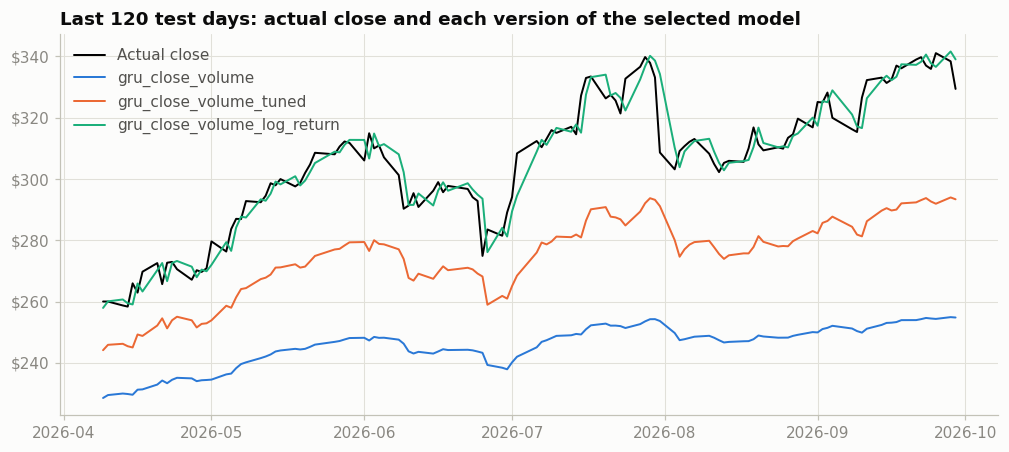

In [ ]:
df = load_stock_data(start_date=None, verbose=False)
rows = []
for name in IMPROVEMENT_RUNS:
    artifacts = load_artifacts(config.ARTIFACTS_DIR / name)
    next_day = predict_next_day(artifacts, df)
    replay = simulate_recent(artifacts, df, days=20)
    rows.append({"run": name, "predicted close": next_day["predicted_close"],
                 "predicted change (%)": next_day["predicted_change_pct"],
                 "20-day MAE ($)": replay["error ($)"].abs().mean()})
display(pd.DataFrame(rows).set_index("run").round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
recent = predict_split(selected.model, selected.data).tail(120)
ax.plot(recent.index, recent["actual"], color="black", label="Actual close")
for (name, run), color in zip(IMPROVEMENT_RUNS.items(), plotting.SERIES):
    ax.plot(recent.index, predict_split(run.model, run.data).tail(120)["predicted"], color=color, label=name)
ax.set_title("Last 120 test days: actual close and each version of the selected model")
plotting._dollar_axis(ax)
ax.legend(loc="upper left")
plotting.save_figure(fig, "improvements_last120.png")
plt.show()

## Results of the improvements

**Hyperparameter tuning.** KerasTuner tried 20 combinations. The best used 128 units, a dropout rate of 0.2, a learning rate of about 0.00133, and a batch size of 32. That trial reached a validation loss of 0.0040, and retraining with the same settings reached 0.0048, compared with 0.0053 for the original model. The gap between the trial and the retrained model shows how much a single training run can vary.

Tuning clearly helped: validation RMSE improved from \$3.46 to \$3.27, test RMSE fell from \$32.54 to \$16.65, and the 20-day replay MAE fell from \$78.24 to \$42.01. However, the tuned model still sits well below the actual price in the recent period, and it did not beat the baselines or the original CNN Close-only model (\$14.76).

**Log-return target.** The log-return model had the lowest validation RMSE of the three versions (\$2.73), so it is the best version under the rule set in advance. Its validation loss (0.3914) is on a different scale and cannot be compared with the others. Predicting returns removed the price-level problem: test RMSE fell to \$4.17, the 20-day replay MAE fell to \$3.85, and its next-day prediction of \$330.49 (+0.33%) is close to the last close of \$329.40.

It still did not beat the baselines. On the test set, its RMSE of \$4.17 compares with \$4.15 for drift and \$4.16 for naive, its MAE of \$2.86 compares with \$2.84 and \$2.85, and its directional accuracy of 53.80% is below drift's 55.22%. The same holds on the validation set, where naive and drift both have an RMSE of \$2.71. The replay chart shows its predictions following the actual price with about a one-day lag, so it appears to add little beyond predicting little or no change from the last close.

**Conclusion.** Both improvements reduced the errors of the selected model, and the log-return target reduced them the most, but no model outperformed the simple baselines. These results come from one chronological split of one stock, and the available evidence does not support real-money deployment of any of these models.

**Remaining issues and future work**

* **Evaluation discipline:** keep the chronological test set separate from model selection, and repeat experiments over additional time periods and stocks before considering practical use.
* **Future experiments:** rolling retraining, alternative scaling methods, additional architectures, and more information sources such as market context or news sentiment, using validation data for tuning.
* **Shuffling:** training windows are kept in chronological order, as the proposal specifies. Testing shuffled windows within the training set is another possible experiment.
* **Reproducibility:** results vary slightly between computers, and GPU training may not repeat exactly. The saved outputs come from a CPU run, which gives the same numbers as the single notebook (`Team7_Deep_Learning_Final_Project.ipynb`).